In [ ]:
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/cv-longtail"

import sys
sys.path.append(ROOT)

import torch
print("GPU available:", torch.cuda.is_available())

Mounted at /content/drive
GPU available: False


In [ ]:
import importlib.util

spec = importlib.util.spec_from_file_location(
    "run",
    ROOT + "/run.py"
)

run = importlib.util.module_from_spec(spec)
spec.loader.exec_module(run)

# Override the shared file's hardcoded path locally
run.BASE = ROOT

print("Loaded:", run.__file__)
print("BASE:", run.BASE)

Loaded: /content/drive/MyDrive/cv-longtail/run.py
BASE: /content/drive/MyDrive/cv-longtail


In [ ]:
# Keep the corrected path
run.BASE = ROOT

cfg = {
    "dataset": "cifar10",
    "imbalance": 100,
    "epochs": 200,
    "batch_size": 128,
    "lr": 0.1,
    "wd": 2e-4
}

for loss in ["reweighted_ce", "balanced_softmax", "cb", "focal"]:
    for sd in [0, 1, 2]:
        run.run({**cfg, "seed": sd, "loss": loss})

train size: 12306 | counts: [4990, 2987, 1786, 1067, 635, 377, 222, 129, 73, 40]
epoch 0 lr=0.02000 loss=2.6634 train_acc=0.138 (7.1s) test_acc=0.1498
epoch 1 lr=0.04000 loss=2.2096 train_acc=0.233 (6.9s)
epoch 2 lr=0.06000 loss=2.1622 train_acc=0.260 (5.4s)
epoch 3 lr=0.08000 loss=2.0473 train_acc=0.308 (5.9s)
epoch 4 lr=0.10000 loss=2.0158 train_acc=0.270 (6.4s)
epoch 5 lr=0.10000 loss=1.9457 train_acc=0.309 (5.4s)
epoch 6 lr=0.10000 loss=1.9618 train_acc=0.304 (7.0s)
epoch 7 lr=0.10000 loss=1.9403 train_acc=0.308 (5.4s)
epoch 8 lr=0.10000 loss=1.8451 train_acc=0.363 (6.4s)
epoch 9 lr=0.10000 loss=1.8066 train_acc=0.369 (6.2s)
epoch 10 lr=0.10000 loss=1.7893 train_acc=0.360 (5.5s) test_acc=0.3440
epoch 11 lr=0.10000 loss=1.7544 train_acc=0.387 (6.1s)
epoch 12 lr=0.10000 loss=1.7636 train_acc=0.363 (5.5s)
epoch 13 lr=0.10000 loss=1.7467 train_acc=0.371 (7.1s)
epoch 14 lr=0.10000 loss=1.7047 train_acc=0.412 (5.5s)
epoch 15 lr=0.10000 loss=1.6363 train_acc=0.417 (6.7s)
epoch 16 lr=0.100

In [ ]:
import os
files = sorted(f for f in os.listdir(f"{ROOT}/results") if f.endswith(".json"))
print(len(files))
for f in files: print(f)

21
cifar10_balanced_softmax_rho100_seed0.json
cifar10_balanced_softmax_rho100_seed1.json
cifar10_balanced_softmax_rho100_seed2.json
cifar10_cb_rho100_seed0.json
cifar10_cb_rho100_seed1.json
cifar10_cb_rho100_seed2.json
cifar10_ce_rho100_seed0.json
cifar10_ce_rho100_seed1.json
cifar10_ce_rho100_seed2.json
cifar10_crt_rho100_seed0.json
cifar10_crt_rho100_seed1.json
cifar10_crt_rho100_seed2.json
cifar10_focal_rho100_seed0.json
cifar10_focal_rho100_seed1.json
cifar10_focal_rho100_seed2.json
cifar10_reweighted_ce_rho100_seed0.json
cifar10_reweighted_ce_rho100_seed1.json
cifar10_reweighted_ce_rho100_seed2.json
cifar10_taunorm_rho100_seed0.json
cifar10_taunorm_rho100_seed1.json
cifar10_taunorm_rho100_seed2.json


{'ERM': [0, 1, 2], 'Reweighted CE': [0, 1, 2], 'Focal': [0, 1, 2], 'CB': [0, 1, 2], 'Balanced softmax': [0, 1, 2], 'tau-norm': [0, 1, 2], 'cRT': [0, 1, 2]}
## Mean ± std over seeds (test accuracy %, sample std)

| method | seeds | overall | many | medium | few |
|---|---|---|---|---|---|
| ERM | 3 | 69.39 ± 0.74 | 92.59 ± 0.62 | 71.23 ± 0.94 | 43.74 ± 2.21 |
| Reweighted CE | 3 | 69.39 ± 1.48 | 86.41 ± 1.02 | 70.71 ± 1.38 | 50.62 ± 2.84 |
| Focal | 3 | 68.82 ± 0.63 | 92.42 ± 1.08 | 70.55 ± 1.24 | 42.91 ± 1.49 |
| CB | 3 | 69.27 ± 1.88 | 87.16 ± 1.29 | 69.74 ± 2.29 | 50.76 ± 2.26 |
| Balanced softmax | 3 | 77.97 ± 0.85 | 90.43 ± 0.20 | 75.77 ± 1.07 | 68.43 ± 1.36 |
| tau-norm | 3 | 75.09 ± 2.09 | 89.59 ± 3.60 | 74.56 ± 0.92 | 61.29 ± 10.14 |
| cRT | 3 | 73.95 ± 0.98 | 91.68 ± 0.96 | 74.30 ± 1.24 | 55.74 ± 1.89 |

## Per seed (overall / many / medium / few)

- ERM seed 0: 70.23 / 93.17 / 71.40 / 45.73
- ERM seed 1: 68.82 / 91.93 / 72.08 / 41.37
- ERM seed 2: 69.13 / 92.67 / 70.23 / 44.13

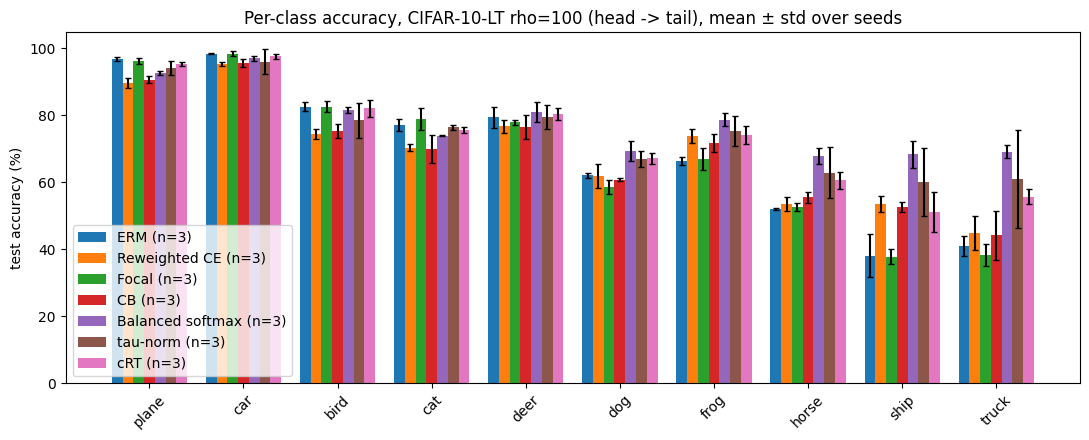

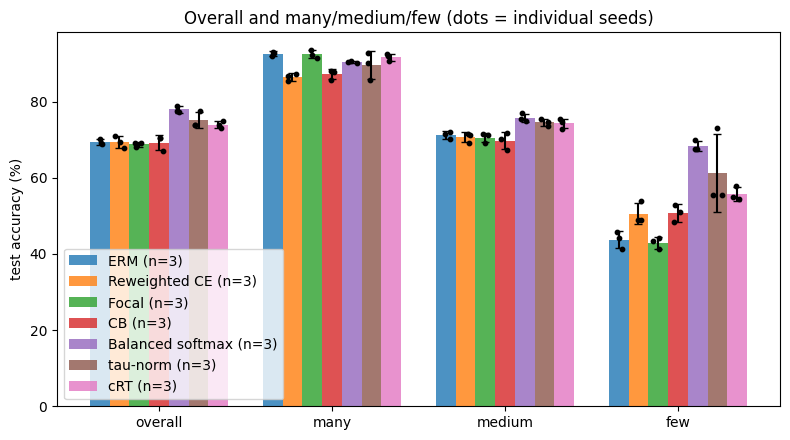

no logs yet: curves need runs started after the run.py patch


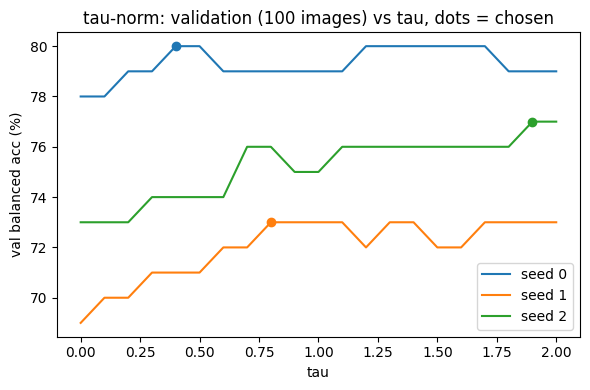

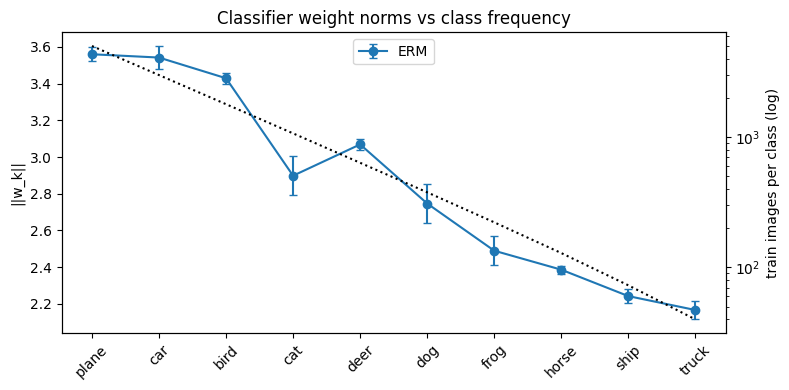

In [ ]:
import importlib, plots
importlib.reload(plots)
plots.make_all()